In [1]:
import cv2
from concurrent.futures import ProcessPoolExecutor, as_completed
from mtcnn import MTCNN
import fcntl
import shutil
import math
import mplcursors
import albumentations as A
import seaborn as sns
import random
import csv
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
from scipy.io import loadmat
from tqdm import tqdm
import os
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import re

I0000 00:00:1792521247.517276   55853 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792521247.561657   55853 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792521249.001366   55853 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
db_folder = '../Photometric_DB'
total_cores = os.cpu_count() - 2

In [3]:
session_paths = []

for id in os.listdir(db_folder):
    if id.isdigit():
        id_path = os.path.join(db_folder, id)
        for session in os.listdir(id_path):
            session_path = os.path.join(id_path, session)
            if os.path.isdir(session_path):
                session_paths.append(session_path)

# 1. Download model facelandmark

In [4]:
# # Chạy đoạn code Python nhỏ này một lần duy nhất để tải file model chính thức từ Google về cùng thư mục làm việc:
# import urllib.request

# url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task"
# model_path = "face_landmarker.task"

# urllib.request.urlretrieve(url, model_path)
# print("Đã tải xong file face_landmarker.task!")

# 2. Face crop

## 2.1. Crop toàn bộ dataset lần 1

In [5]:
MODEL_PATH = 'face_landmarker.task'
ERROR_LOG = "3_face_crop_error.csv"

# Khởi tạo Cấu hình Options Toàn cục theo chuẩn mới
base_options = python.BaseOptions(model_asset_path=MODEL_PATH)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,  # Đảm bảo chạy ở chế độ ảnh tĩnh
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False,
    num_faces=2,
    min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5
)

landmarker = None

def init_worker():
    global landmarker

    landmarker = vision.FaceLandmarker.create_from_options(options)

In [6]:
def detect_face_mesh(image_path):
    global landmarker
    
    image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)

    # 1. Chuyển ảnh về uint8
    if image.dtype == np.uint16:
        # Tương đương ánh xạ dải 16-bit sang 8-bit
        image_uint8 = (image / 257).astype(np.uint8)
    elif image.dtype == np.uint8:
        image_uint8 = image.copy()
    else:
        raise TypeError(f'Kiểu dữ liệu PNG không được hỗ trợ: {image.dtype}')

    # 2. Chuẩn hóa số kênh thành RGB
    if image_uint8.ndim == 2:
        # Ảnh xám 1 kênh
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_GRAY2RGB)
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
        # OpenCV đọc ảnh màu theo thứ tự BGR
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGR2RGB)
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGRA2RGB)
    else:
        raise ValueError(f'Kích thước ảnh không được hỗ trợ: {image_uint8.shape}')

    # 3. Tạo đối tượng mp.Image từ mảng numpy RGB chuẩn hóa
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_image)

    # 4. Chạy FaceLandmarker
    results = landmarker.detect(mp_image)
    
    return results

In [7]:
def get_face_bounding_box(image_path, landmarks, padding=0.20):
    """
    Tính bounding box vuông từ Face Mesh landmark.

    Args:
        image_path: Đường dẫn ảnh gốc.
        landmarks: Danh sách điểm mốc khuôn mặt, là đầu ra của mediapipe, cần đưa về dạng tọa độ
        padding: Tỷ lệ padding mỗi phía, ví dụ 0.10 = 10%. 

    Returns:
        (x0, y0, x1, y1): Bounding box trên ảnh gốc.
        None: Không phát hiện được khuôn mặt.

    Raises:
        ValueError: Phát hiện nhiều khuôn mặt hoặc box không hợp lệ.
    """

    image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
    
    # 1. Chuyển ảnh về uint8
    if image.dtype == np.uint16:
        # Tương đương ánh xạ dải 16-bit sang 8-bit
        image_uint8 = (image / 257).astype(np.uint8)
    elif image.dtype == np.uint8:
        image_uint8 = image.copy()
    else:
        raise TypeError(f'Kiểu dữ liệu PNG không được hỗ trợ: {image.dtype}')

    # 2. Chuẩn hóa số kênh thành RGB
    if image_uint8.ndim == 2:
        # Ảnh xám 1 kênh
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_GRAY2RGB)
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
        # OpenCV đọc ảnh màu theo thứ tự BGR
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGR2RGB)
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
        rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGRA2RGB)
    else:
        raise ValueError(f'Kích thước ảnh không được hỗ trợ: {image_uint8.shape}')

    h, w = image.shape[:2]

    landmark_points = [
        (int(round(lm.x * w)), int(round(lm.y * h)))
        for lm in landmarks
    ]

    if not landmark_points:
        raise ValueError(f"Không có landmark: {image_path}")

    xs = [x for x, _ in landmark_points]
    ys = [y for _, y in landmark_points]

    x_min, x_max = min(xs), max(xs)
    y_min, y_max = min(ys), max(ys)

    face_w = x_max - x_min
    face_h = y_max - y_min

    if face_w <= 0 or face_h <= 0:
        raise ValueError(
            f"Bounding box không hợp lệ: {image_path}"
        )

    # 1. Thêm padding
    pad_x = int(round(face_w * padding))
    pad_y = int(round(face_h * padding))

    x_min -= pad_x
    x_max += pad_x
    y_min -= pad_y
    y_max += pad_y

    # 2. Thu nhỏ dần nếu cả hai chiều đều vượt biên
    #    Mỗi lần thu nhỏ 1 pixel ở mỗi cạnh đang vượt biên.
    while True:
        overflow_x = x_min < 0 or x_max > w
        overflow_y = y_min < 0 or y_max > h

        # Không còn chiều nào vượt biên
        if not overflow_x and not overflow_y:
            break

        # Chỉ còn một chiều vượt biên: dừng
        if overflow_x != overflow_y:
            break

        # Cả hai chiều đều vượt biên: thu nhỏ cả hai
        if x_min < 0:
            x_min += 1
        if x_max > w:
            x_max -= 1

        if y_min < 0:
            y_min += 1
        if y_max > h:
            y_max -= 1

    # 3. Xử lý chiều còn vượt biên
    #    Nếu cả hai đầu của cùng một chiều vượt biên,
    #    thu nhỏ cho đến khi chỉ còn một đầu vượt biên.
    while (x_min < 0 and x_max > w) or (
        y_min < 0 and y_max > h
    ):
        if x_min < 0 and x_max > w:
            x_min += 1
            x_max -= 1

        if y_min < 0 and y_max > h:
            y_min += 1
            y_max -= 1

    # 4. Xác định box có vuông hay không
    box_w = x_max - x_min
    box_h = y_max - y_min
    is_square = box_w == box_h

    return {
        "box": (x_min, y_min, x_max, y_max),
        "is_square": is_square,
        "status": "square" if is_square else "not_square",
        "padding": padding,
    }

In [10]:
def crop_face(image_path, image_type, bbox_result, resize=256):
    image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)

    if image is None:
        raise FileNotFoundError(
            f"Không đọc được ảnh: {image_path}"
        )

    # 0. Xác định giá trị padding theo loại ảnh
    if image_type == "normalmap":
        padding_value = 0.5
    elif image_type == "albedo" or image_type == "rgb":
        padding_value = 0.0
    elif image_type == "depth":
        padding_value = 0
    else:
        raise ValueError(
            f"Loại ảnh không hợp lệ: {image_type}"
        )

    # 1. Chuyển ảnh về uint8
    if image.dtype == np.uint16:
        image_uint8 = (image / 257).astype(np.uint8)
    elif image.dtype == np.uint8:
        image_uint8 = image.copy()
    else:
        raise TypeError(
            f"Kiểu dữ liệu PNG không được hỗ trợ: {image.dtype}"
        )

    # 2. Chuẩn hóa số kênh thành RGB
    if image_uint8.ndim == 2:
        rgb_image = cv2.cvtColor(
            image_uint8, cv2.COLOR_GRAY2RGB
        )
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
        rgb_image = cv2.cvtColor(
            image_uint8, cv2.COLOR_BGR2RGB
        )
    elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
        rgb_image = cv2.cvtColor(
            image_uint8, cv2.COLOR_BGRA2RGB
        )
    else:
        raise ValueError(
            f"Kích thước ảnh không được hỗ trợ: {image_uint8.shape}"
        )

    h, w = rgb_image.shape[:2]

    # 3. Lấy thông tin từ kết quả get_face_bounding_box()
    x_min, y_min, x_max, y_max = map(
        int, bbox_result["box"]
    )
    is_square = bbox_result["is_square"]

    box_w = x_max - x_min
    box_h = y_max - y_min

    if box_w <= 0 or box_h <= 0:
        raise ValueError(
            f"Bounding box không hợp lệ: {bbox_result['box']}"
        )

    # 4. Xác định vùng crop vuông
    if is_square:
        crop_x_min = x_min
        crop_y_min = y_min
        side = box_w
    else:
        side = max(box_w, box_h)

        # Giữ tâm bounding box, mở rộng cạnh ngắn
        center_x = (x_min + x_max) / 2
        center_y = (y_min + y_max) / 2

        crop_x_min = int(np.floor(center_x - side / 2))
        crop_y_min = int(np.floor(center_y - side / 2))

    crop_x_max = crop_x_min + side
    crop_y_max = crop_y_min + side

    # 5. Chuyển padding_value sang miền uint8
    # Normal map: 0.5 trong [0, 1] tương ứng khoảng 128 trong [0, 255]
    if image_type == "normalmap":
        pad_value = int(round(padding_value * 255))
    else:
        pad_value = int(padding_value)

    # Tạo canvas vuông, ban đầu lấp đầy bằng padding
    crop = np.full(
        (side, side, 3),
        fill_value=pad_value,
        dtype=np.uint8,
    )

    # 6. Tìm vùng giao giữa crop và ảnh gốc
    src_x_min = max(0, crop_x_min)
    src_y_min = max(0, crop_y_min)
    src_x_max = min(w, crop_x_max)
    src_y_max = min(h, crop_y_max)

    # Copy vùng ảnh hợp lệ vào canvas
    if src_x_min < src_x_max and src_y_min < src_y_max:
        dst_x_min = src_x_min - crop_x_min
        dst_y_min = src_y_min - crop_y_min

        dst_x_max = dst_x_min + (src_x_max - src_x_min)
        dst_y_max = dst_y_min + (src_y_max - src_y_min)

        crop[dst_y_min:dst_y_max, dst_x_min:dst_x_max] = (
            rgb_image[
                src_y_min:src_y_max,
                src_x_min:src_x_max,
            ]
        )

    # 7. Resize về kích thước đầu ra
    crop_resized = cv2.resize(
        crop,
        (resize, resize),
        interpolation=cv2.INTER_LINEAR,
    )

    return crop_resized

In [11]:
def process_session(session_path):
    """
    Xử lý ảnh trong một session:
    1. Detect khuôn mặt từ albedo.png.
    2. Tính bounding box từ landmarks của albedo.
    3. Dùng cùng bounding box để crop albedo, normalmap và depthmap.
    4. Lưu các ảnh crop trong session_path.

    Nếu không phát hiện đúng 1 khuôn mặt:
    ghi log lỗi và bỏ qua session.
    """

    # 1. Đường dẫn ảnh albedo
    albedo_path = os.path.join(session_path, "albedo.png")

    if not os.path.isfile(albedo_path):
        print(f"[ERROR] Không tìm thấy ảnh: {albedo_path}")
        _log_crop_error(session_path, 0)
        return None

    # 2. Detect landmarks từ albedo
    try:
        detection = detect_face_mesh(albedo_path)
    except Exception as exc:
        print(f"[ERROR] Detect thất bại: {albedo_path}: {exc}")
        _log_crop_error(session_path, -1)
        return None

    # 3. Kiểm tra số lượng khuôn mặt
    face_landmarks_list = detection.face_landmarks
    face_count = len(face_landmarks_list)

    if face_count != 1:
        _log_crop_error(session_path, face_count)
        print(
            f"[SKIP] Phát hiện {face_count} khuôn mặt: "
            f"{session_path}"
        )
        return None

    # 4. Tính bounding box duy nhất từ albedo
    landmarks = face_landmarks_list[0]

    try:
        bbox_result = get_face_bounding_box(
            image_path=albedo_path,
            landmarks=landmarks,
            padding=0.1,
        )
    except Exception as exc:
        print(
            f"[ERROR] Tính bounding box thất bại: "
            f"{albedo_path}: {exc}"
        )
        _log_crop_error(session_path, -1)
        return None

    # 5. Cấu hình các ảnh cần crop
    images_to_crop = [
        ("im0.bmp", "rgb", "im0_crop.png"),
        ("im1.bmp", "rgb", "im1_crop.png"),
        ("im2.bmp", "rgb", "im2_crop.png"),
        ("im3.bmp", "rgb", "im3_crop.png"),
        ("albedo.png", "albedo", "albedo_crop.png"),
        ("normalmap.png", "normalmap", "normalmap_crop.png"),
        ("depthmap.png", "depth", "depthmap_crop.png"),
    ]

    outputs = {}

    # 6. Crop tất cả ảnh bằng cùng bbox_result
    for input_name, image_type, output_name in images_to_crop:
        image_path = os.path.join(session_path, input_name)
        output_path = os.path.join(session_path, output_name)

        if not os.path.isfile(image_path):
            print(f"[ERROR] Không tìm thấy ảnh: {image_path}")
            continue

        try:
            face_crop = crop_face(
                image_path=image_path,
                image_type=image_type,
                bbox_result=bbox_result,
                resize=256,
            )

            # crop_face trả RGB; chuyển sang BGR để ghi bằng OpenCV
            face_crop_bgr = cv2.cvtColor(
                face_crop,
                cv2.COLOR_RGB2BGR,
            )

            if not cv2.imwrite(output_path, face_crop_bgr):
                raise IOError(f"Không thể ghi ảnh: {output_path}")

            outputs[output_name] = output_path

        except Exception as exc:
            print(
                f"[ERROR] Crop thất bại: {image_path}: {exc}"
            )

    # 7. Trả về kết quả
    return {
        "session_path": session_path,
        "face_count": face_count,
        "bbox_result": bbox_result,
        "outputs": outputs,
    }


def _log_crop_error(session_path, face_count):
    """
    Ghi nối tiếp lỗi vào 3.face_crop_error.csv.
    face_count = 0: không phát hiện khuôn mặt.
    face_count >= 2: phát hiện nhiều khuôn mặt.
    face_count = -1: detect phát sinh exception, chưa xác định được số mặt.
    """

    log_path = ERROR_LOG
    file_exists = os.path.isfile(log_path)

    with open(
        log_path,
        mode="a",
        newline="",
        encoding="utf-8",
    ) as f:
        writer = csv.writer(f)

        if not file_exists or os.path.getsize(log_path) == 0:
            writer.writerow(["session_path", "face_count"])

        writer.writerow([session_path, face_count])

In [12]:
with ProcessPoolExecutor(
    max_workers=total_cores,
    initializer=init_worker,
) as executor:
    list(
        tqdm(
            executor.map(process_session, session_paths),
            total=len(session_paths),
        )
    )

W0000 00:00:1792521414.933606   56321 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933603   56324 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933613   56334 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933663   56322 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933698   56323 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933754   56325 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.935398   56337 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933805   56326 face_landmarker_graph.cc:180] Sets FaceBlendshapesGr

[SKIP] Phát hiện 2 khuôn mặt: ../Photometric_DB/1009/2009-07-09_12-27-07


 11%|█         | 347/3159 [00:06<00:42, 65.46it/s]

[SKIP] Phát hiện 2 khuôn mặt: ../Photometric_DB/1009/2009-10-08_14-46-23


 23%|██▎       | 726/3159 [00:13<00:45, 53.23it/s]

...

 94%|█████████▍| 2979/3159 [00:54<00:02, 61.28it/s]

[SKIP] Phát hiện 0 khuôn mặt: ../Photometric_DB/2176/2007-12-04_10-23-20


 95%|█████████▍| 3000/3159 [00:54<00:02, 56.06it/s]

[SKIP] Phát hiện 0 khuôn mặt: ../Photometric_DB/2180/2007-12-05_13-27-28


100%|██████████| 3159/3159 [00:57<00:00, 55.23it/s]WARNING: Logging before InitGoogle() is written to STDERR
W0000 00:00:1792521414.933663   56322 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933698   56323 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933754   56325 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.935398   56337 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792521414.933805   56326 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.



In [ ]:
for session_path in session_paths:
    abedo_crop_path = os.path.join(session_path, "albedo_crop.png")
    if os.path.exists(abedo_crop_path):
        os.remove(abedo_crop_path)

1. Sau khi chạy đoạn code trên, sẽ gen ra thêm các ảnh albedo_crop, normalmap_crop, deepmap_crop. Thuật toán crop
    - Dùng mediapipe xác định các điểm landmarks => Tạo ra bounding box cơ sở là x_min, x_max, y_min, y_max từ các điểm landmarks đó.
    - Thực hiện mở rộng bounding box thêm padding (20%) ở các chiều thành bounding box mới.
    - Đưa bounding box mới về dạng ô vuông nếu có thể. Trong trường hợp không thể thành ô vuông, giữ nguyên cạnh lớn nhất và mở rộng cạnh còn lại tối đa có thể. Giả sử cạnh phải mở rộng là x => Mở rộng x_min, x_max tối đa sao cho không vượt biên.
2. Thuật toán trên không xử lý các ảnh có 2 khuôn mặt hay không detect được khuôn măt. Link các session được ghi trong file '3_face_crop_error.csv'

## 2.2. Xử lý các ảnh detect được 2 khuôn mặt trở lên

In [81]:
df = pd.read_csv(ERROR_LOG)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   session_path  33 non-null     str  
 1   face_count    33 non-null     int64
dtypes: int64(1), str(1)
memory usage: 660.0 bytes


In [82]:
df_2_faces = df[df['face_count'] == 2]
df_2_faces.count()

session_path    5
face_count      5
dtype: int64

In [83]:
df_2_faces.head(6)

,session_path,face_count
0,../Photometric_DB/1009/2009-07-09_12-27-07,2
1,../Photometric_DB/1009/2009-10-08_14-46-23,2
14,../Photometric_DB/1066/2009-07-30_07-19-40,2
24,../Photometric_DB/1205/2008-12-16_14-30-03,2
29,../Photometric_DB/2115/2008-03-18_17-35-14,2


In [106]:
session_path_2_faces = df_2_faces.iloc[4]['session_path']
session_path_2_faces

'../Photometric_DB/2115/2008-03-18_17-35-14'

In [107]:
if landmarker is None:
    landmarker = vision.FaceLandmarker.create_from_options(options)

Phát hiện được 2 khuôn mặt.


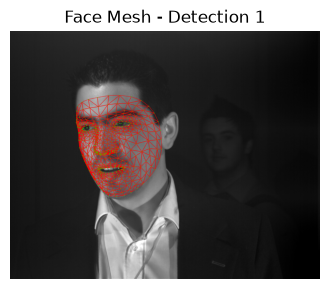

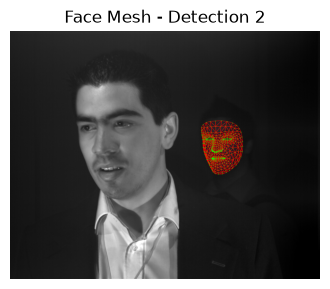

In [108]:
# Đường dẫn ảnh của session cần kiểm tra
albedo_path = os.path.join(session_path_2_faces, "albedo.png")

# Phát hiện khuôn mặt bằng hàm ban đầu
detection_2_faces = detect_face_mesh(albedo_path)

# Đọc ảnh để vẽ
albedo = cv2.imread(albedo_path, cv2.IMREAD_UNCHANGED)

if albedo is None:
    raise FileNotFoundError(f"Không đọc được ảnh: {albedo_path}")

# Chuẩn hóa ảnh về uint8
if albedo.dtype == np.uint16:
    image_uint8 = (albedo / 257).astype(np.uint8)
elif albedo.dtype == np.uint8:
    image_uint8 = albedo.copy()
else:
    raise TypeError(f"Kiểu dữ liệu không được hỗ trợ: {albedo.dtype}")

# Chuyển ảnh về RGB
if image_uint8.ndim == 2:
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_GRAY2RGB)
elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGR2RGB)
elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGRA2RGB)
else:
    raise ValueError(f"Kích thước ảnh không được hỗ trợ: {image_uint8.shape}")

# Ảnh dùng để vẽ bằng OpenCV (BGR)
overlay = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2BGR)
h, w = rgb_image.shape[:2]

# Lấy danh sách landmark của tất cả khuôn mặt
all_faces = detection_2_faces.face_landmarks
print(f"Phát hiện được {len(all_faces)} khuôn mặt.")

# Vẽ Face Mesh cho từng khuôn mặt
connections = vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION

for face_idx, face_landmarks in enumerate(all_faces):
    # Tạo bản sao ảnh gốc cho từng khuôn mặt
    overlay = cv2.cvtColor(rgb_image.copy(), cv2.COLOR_RGB2BGR)

    points = [
        (int(round(lm.x * w)), int(round(lm.y * h)))
        for lm in face_landmarks
    ]

    # Chỉ vẽ mesh của khuôn mặt hiện tại
    for connection in connections:
        s, e = connection.start, connection.end

        if s < len(points) and e < len(points):
            cv2.line(
                overlay,
                points[s],
                points[e],
                (0, 0, 255),
                1,
                lineType=cv2.LINE_AA,
            )

    # Vẽ các điểm landmark
    for x, y in points:
        cv2.circle(
            overlay,
            (x, y),
            1,
            (0, 255, 0),
            -1,
            lineType=cv2.LINE_AA,
        )

    # Hiển thị mỗi khuôn mặt trong một figure riêng
    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"Face Mesh - Detection {face_idx + 1}")
    plt.axis("off")
    plt.show()


In [109]:
def process_session_2_faces(session_path, choosen):
    """
    Xử lý ảnh trong một session:
    1. Detect khuôn mặt từ albedo.png.
    2. Tính bounding box từ landmarks của albedo.
    3. Dùng cùng bounding box để crop albedo, normalmap và depthmap.
    4. Lưu các ảnh crop trong session_path.

    Nếu không phát hiện đúng 1 khuôn mặt:
    ghi log lỗi và bỏ qua session.
    """

    # 1. Đường dẫn ảnh albedo
    albedo_path = os.path.join(session_path, "albedo.png")

    if not os.path.isfile(albedo_path):
        print(f"[ERROR] Không tìm thấy ảnh: {albedo_path}")
        return None

    # 2. Detect landmarks từ albedo
    try:
        detection = detect_face_mesh(albedo_path)
    except Exception as exc:
        print(f"[ERROR] Detect thất bại: {albedo_path}: {exc}")
        return None

    # 3. Kiểm tra số lượng khuôn mặt
    face_landmarks_list = detection.face_landmarks
    face_count = len(face_landmarks_list)

    if face_count != 2:
        raise Exception (f"[SKIP] Phát hiện {face_count} khuôn mặt: {session_path}, không phải 2")
    
    if choosen not in [0, 1]:
        raise ValueError(f"Choosen chỉ có thể là 0 hoặc 1")
    
    # 4. Tính bounding box duy nhất từ albedo
    landmarks = face_landmarks_list[choosen]

    try:
        bbox_result = get_face_bounding_box(
            image_path=albedo_path,
            landmarks=landmarks,
            padding=0.10,
        )
    except Exception as exc:
        print(
            f"[ERROR] Tính bounding box thất bại: "
            f"{albedo_path}: {exc}"
        )
        return None

    # 5. Cấu hình các ảnh cần crop
    images_to_crop = [
        ("im0.bmp", "rgb", "im0_crop.png"),
        ("im1.bmp", "rgb", "im1_crop.png"),
        ("im2.bmp", "rgb", "im2_crop.png"),
        ("im3.bmp", "rgb", "im3_crop.png"),
        ("albedo.png", "albedo", "albedo_crop.png"),
        ("normalmap.png", "normalmap", "normalmap_crop.png"),
        ("depthmap.png", "depth", "depthmap_crop.png"),
    ]

    outputs = {}

    # 6. Crop tất cả ảnh bằng cùng bbox_result
    for input_name, image_type, output_name in images_to_crop:
        image_path = os.path.join(session_path, input_name)
        output_path = os.path.join(session_path, output_name)

        if not os.path.isfile(image_path):
            print(f"[ERROR] Không tìm thấy ảnh: {image_path}")
            continue

        try:
            face_crop = crop_face(
                image_path=image_path,
                image_type=image_type,
                bbox_result=bbox_result,
                resize=256,
            )

            # crop_face trả RGB; chuyển sang BGR để ghi bằng OpenCV
            face_crop_bgr = cv2.cvtColor(
                face_crop,
                cv2.COLOR_RGB2BGR,
            )

            if not cv2.imwrite(output_path, face_crop_bgr):
                raise IOError(f"Không thể ghi ảnh: {output_path}")

            outputs[output_name] = output_path

        except Exception as exc:
            print(
                f"[ERROR] Crop thất bại: {image_path}: {exc}"
            )

    # 7. Trả về kết quả
    return {
        "session_path": session_path,
        "face_count": face_count,
        "bbox_result": bbox_result,
        "outputs": outputs,
    }

In [110]:
process_session_2_faces(session_path_2_faces, choosen=0)

{'session_path': '../Photometric_DB/2115/2008-03-18_17-35-14',
 'face_count': 2,
 'bbox_result': {'box': (238, 223, 661, 725),
  'is_square': False,
  'status': 'not_square',
  'padding': 0.1},
 'outputs': {'im0_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/im0_crop.png',
  'im1_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/im1_crop.png',
  'im2_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/im2_crop.png',
  'im3_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/im3_crop.png',
  'albedo_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/albedo_crop.png',
  'normalmap_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/normalmap_crop.png',
  'depthmap_crop.png': '../Photometric_DB/2115/2008-03-18_17-35-14/depthmap_crop.png'}}

In [111]:
df = df[df['face_count'] != 2]

df.to_csv(ERROR_LOG, index=False)

1. Thực hiện detect bằng tay 6 session detect được 2 mặt trong file 3_face_crop_error.csv
2. Lưu ý điều chỉnh choosen và tham số padding trong hàm get_bouding_box trong hàm process_session_2_faces cho hợp lý để tránh crop ra vẫn còn mặt 2 người '../Photometric_DB/1009/2009-10-08_14-46-23'
3. Xóa các session đã xử lý ra khởi file 3_face_crop_error.csv

## 2.3. Xử lý dataset không detect mặt được bằng mediapipe

In [113]:
df = pd.read_csv(ERROR_LOG)
df_0_faces = df[df["face_count"] == 0]

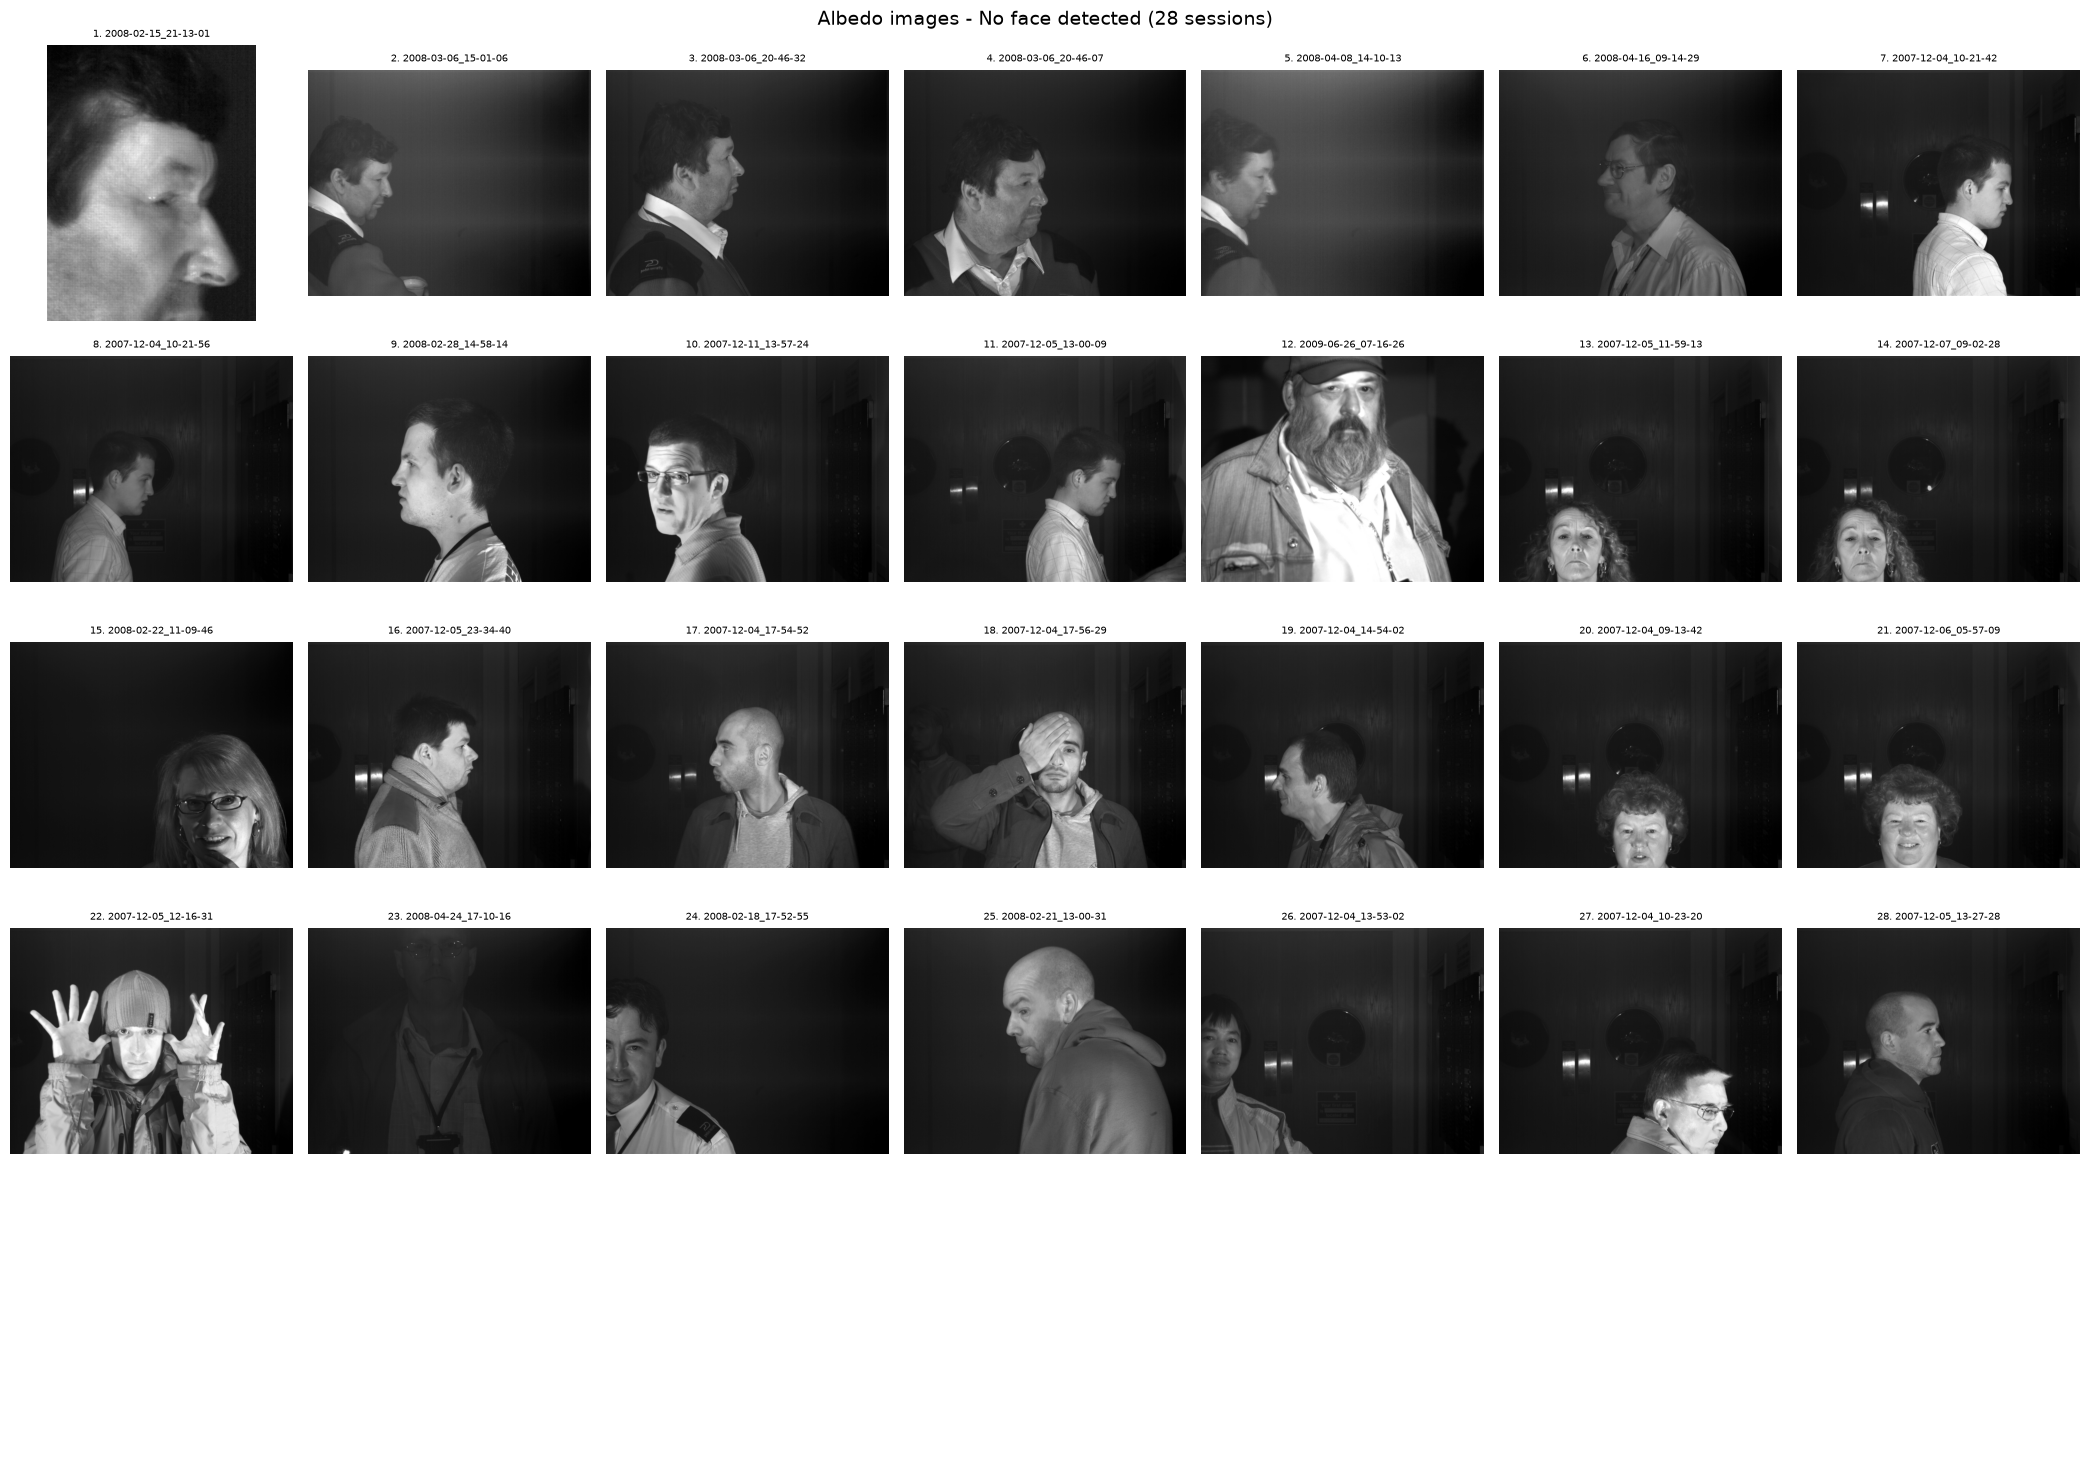

In [114]:
session_paths_0_faces = df_0_faces["session_path"].tolist()

# Figure 5 hàng × 7 cột
nrows, ncols = 5, 7
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(21, 15)
)

axes = axes.flatten()

for i, session_path in enumerate(session_paths_0_faces):
    ax = axes[i]
    image_path = os.path.join(session_path, "albedo.png")

    if not os.path.isfile(image_path):
        ax.set_title("Missing image", fontsize=8)
        ax.axis("off")
        continue

    image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)

    if image is None:
        ax.set_title("Read error", fontsize=8)
        ax.axis("off")
        continue

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"{i + 1}. {os.path.basename(session_path)}",
        fontsize=7
    )
    ax.axis("off")

# Tắt các ô không sử dụng nếu số ảnh ít hơn 35
for i in range(len(session_paths_0_faces), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    f"Albedo images - No face detected ({len(session_paths_0_faces)} sessions)",
    fontsize=14
)
plt.tight_layout()
plt.show()

Đa số các ảnh này đều có pose rất lớn hoặc mất 1 phần khuôn mặt. nên loại bỏ gần như rất nhiều

In [147]:
selected_indices = [17, 18, 19, 20, 25, 26, 27]

# Lấy đúng các session tương ứng với vị trí ảnh đã plot
selected_sessions = [
    session_paths_0_faces[i]
    for i in selected_indices
]

# Tạo DataFrame để tiện xử lý tiếp
df_manual = pd.DataFrame({
    "plot_index": [i + 1 for i in selected_indices],
    "session_path": selected_sessions,
})

print(df_manual.to_string(index=False))

 plot_index                               session_path
         18 ../Photometric_DB/1100/2009-06-26_07-16-26
         19 ../Photometric_DB/2171/2007-12-05_11-59-13
         20 ../Photometric_DB/2171/2007-12-07_09-02-28
         21 ../Photometric_DB/1140/2008-02-22_11-09-46
         26 ../Photometric_DB/1185/2007-12-04_09-13-42
         27 ../Photometric_DB/1185/2007-12-06_05-57-09
         28 ../Photometric_DB/1208/2007-12-05_12-16-31


plot_index                               session_path
         18 ../Photometric_DB/1100/2009-06-26_07-16-26
         19 ../Photometric_DB/2171/2007-12-05_11-59-13
         20 ../Photometric_DB/2171/2007-12-07_09-02-28
         21 ../Photometric_DB/1140/2008-02-22_11-09-46
         26 ../Photometric_DB/1185/2007-12-04_09-13-42
         27 ../Photometric_DB/1185/2007-12-06_05-57-09
         28 ../Photometric_DB/1208/2007-12-05_12-16-31

In [73]:
session_path = '../Photometric_DB/1208/2007-12-05_12-16-31'

In [76]:
albedo_path = os.path.join(session_path, 'albedo.png')
metadata_path = os.path.join(session_path, 'metadata.txt')
albedo_img = cv2.imread(albedo_path, cv2.IMREAD_UNCHANGED)
if albedo_img is None:
    raise FileNotFoundError(f'Không đọc được ảnh: {albedo_path}')

h, w = albedo_img.shape[:2]
print(f'Image size: h={h}, w={w}')


# Đọc 22 giá trị đầu tiên trong metadata: 11 landmark (x, y)
with open(metadata_path, 'r') as f:
    values = np.fromstring(f.read(), sep=' ')

if len(values) < 12:
    raise ValueError(
        f'Metadata không đủ dữ liệu landmark: chỉ có {len(values)} giá trị'
    )

landmarks = values[:22].reshape(-1, 2)

# Landmark thứ 5 và thứ 6
point5 = landmarks[5]
point6 = landmarks[6]

# Trung điểm của hai landmark
center_x, center_y = (point5 + point6) / 2

print(f'Landmark 5: {point5}')
print(f'Landmark 6: {point6}')
print(f'BBox center: ({center_x:.2f}, {center_y:.2f})')


# Số pixel mở rộng từ tâm theo mỗi phía
padding = 200

# Tạo bounding box: (x1, y1, x2, y2)
x1 = round(center_x - padding)
y1 = round(center_y - padding)
x2 = round(center_x + padding)
y2 = round(center_y + padding)

print(x1, x2, y1, y2)

Image size: h=1024, w=1280
Landmark 5: [536. 553.]
Landmark 6: [581. 566.]
BBox center: (558.50, 559.50)
358 758 360 760


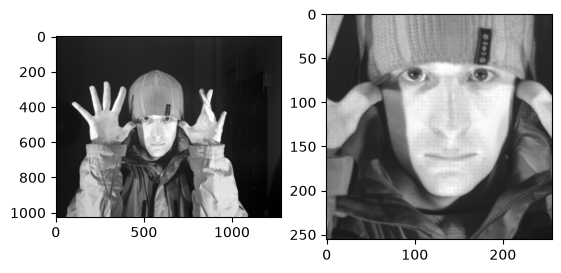

In [77]:
bbox_result = {
    "box": (x1, y1, x2, y2),
    "is_square": False,
    "status": "not_square",
    "padding": None,
}

image = crop_face(albedo_path, 'albedo', bbox_result)
plt.subplot(1,2,1)
plt.imshow(albedo_img, cmap='gray')

plt.subplot(1,2,2)
plt.imshow(image, cmap='gray')
plt.show()

In [78]:
def process_session_0_faces(session_path, bbox_result):
    """
    Xử lý ảnh trong một session:
    1. Detect khuôn mặt từ albedo.png.
    2. Tính bounding box từ landmarks của albedo.
    3. Dùng cùng bounding box để crop albedo, normalmap và depthmap.
    4. Lưu các ảnh crop trong session_path.

    Nếu không phát hiện đúng 1 khuôn mặt:
    ghi log lỗi và bỏ qua session.
    """

    # 1. Đường dẫn ảnh albedo
    albedo_path = os.path.join(session_path, "albedo.png")

    if not os.path.isfile(albedo_path):
        print(f"[ERROR] Không tìm thấy ảnh: {albedo_path}")
        return None

    # 5. Cấu hình các ảnh cần crop
    images_to_crop = [
        ("im0.bmp", "rgb", "im0_crop.png"),
        ("im1.bmp", "rgb", "im1_crop.png"),
        ("im2.bmp", "rgb", "im2_crop.png"),
        ("im3.bmp", "rgb", "im3_crop.png"),
        ("albedo.png", "albedo", "albedo_crop.png"),
        ("normalmap.png", "normalmap", "normalmap_crop.png"),
        ("depthmap.png", "depth", "depthmap_crop.png"),
    ]

    outputs = {}

    # 6. Crop tất cả ảnh bằng cùng bbox_result
    for input_name, image_type, output_name in images_to_crop:
        image_path = os.path.join(session_path, input_name)
        output_path = os.path.join(session_path, output_name)

        if not os.path.isfile(image_path):
            print(f"[ERROR] Không tìm thấy ảnh: {image_path}")
            continue

        try:
            face_crop = crop_face(
                image_path=image_path,
                image_type=image_type,
                bbox_result=bbox_result,
                resize=256,
            )

            # crop_face trả RGB; chuyển sang BGR để ghi bằng OpenCV
            face_crop_bgr = cv2.cvtColor(
                face_crop,
                cv2.COLOR_RGB2BGR,
            )

            if not cv2.imwrite(output_path, face_crop_bgr):
                raise IOError(f"Không thể ghi ảnh: {output_path}")

            outputs[output_name] = output_path

        except Exception as exc:
            print(
                f"[ERROR] Crop thất bại: {image_path}: {exc}"
            )

    # 7. Trả về kết quả
    return {
        "session_path": session_path,
        "bbox_result": bbox_result,
        "outputs": outputs,
    }

In [79]:
process_session_0_faces(session_path, bbox_result)

{'session_path': '../Photometric_DB/1208/2007-12-05_12-16-31',
 'bbox_result': {'box': (358, 360, 758, 760),
  'is_square': False,
  'status': 'not_square',
  'padding': None},
 'outputs': {'im0_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/im0_crop.png',
  'im1_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/im1_crop.png',
  'im2_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/im2_crop.png',
  'im3_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/im3_crop.png',
  'albedo_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/albedo_crop.png',
  'normalmap_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/normalmap_crop.png',
  'depthmap_crop.png': '../Photometric_DB/1208/2007-12-05_12-16-31/depthmap_crop.png'}}

In [112]:
# Đọc file đã lọc
df_filtered = pd.read_csv(ERROR_LOG)

# Lấy danh sách session cần loại bỏ
sessions_to_remove = df_manual['session_path'].tolist()

# Xóa các dòng có session_path nằm trong danh sách thủ công
df_filtered = df_filtered[
    ~df_filtered['session_path'].isin(sessions_to_remove)
]

# Ghi đè file _filtered.csv
df_filtered.to_csv(ERROR_LOG, index=False)

NameError: name 'df_manual' is not defined

1. Thực hiện bounding box bằng tay các trường hợp mediapipe ko nhận diện được khuôn mặt
2. Trong các ảnh ko nhận diện được, đa số là các ảnh có pose rất lớn => Không nhận diện bỏ luôn vì task nhận diện khuôn mặt sau cũng bỏ
3. Xóa hết các đường dẫn đã detect bằng tay trong file 3_face_crop_error.csv. File này sau cùng chứa các sesion_path ko có ảnh albedo, normalmap, depthmap đã crop